<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Factorización de matrices: SVD, SGD y NMF</div><div style="opacity:.72;font-size:14px;margin-top:6px;">SVD truncada sobre los residuos del baseline, PureSVD para top-N, SVD regularizada con sesgos entrenada por descenso de gradiente estocástico, NMF con máscara y visualización de los factores latentes con PCA y t-SNE.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

Representar a usuarios y películas con **factores latentes**: vectores de pocas dimensiones cuyo producto punto
aproxima el rating (Koren, Bell y Volinsky, 2009; Leskovec *et al.*, *Mining of Massive Datasets*, sección 9.4).
Comparamos cuatro factorizaciones:

- **SVD truncada** (`scipy.sparse.linalg.svds`) de la matriz de residuos del baseline, con los faltantes como 0;
- **PureSVD** (Cremonesi, Koren y Turrin, 2010): la misma SVD sobre los ratings crudos, pensada para **ordenar** y no
  para predecir;
- **SVD regularizada con sesgos por SGD** (Funk, 2006; Koren, 2008), implementada por nosotros. Solo usa las entradas
  observadas;
- **NMF con máscara:** factores no negativos ajustados solo sobre las entradas observadas, con reglas multiplicativas.

Al final visualizamos los factores de las películas con **PCA** y **t-SNE** para interpretarlos.

### Los datos

Las salidas de los notebooks 1 y 2 en `data/processed/`: `R_train.npz` y `S_R_train.npz` con sus días (para la
validación tipo probe), los arreglos del probe, los sesgos `modelos/baseline_*.npz` y los usuarios de la evaluación
top-N `S_usuarios_topn.npy`.

**Protocolo.** Es el mismo del notebook 2: los hiperparámetros se eligen con la validación tipo probe (el último rating
de cada usuario) y las métricas se calculan sobre el probe. Los modelos de factores se quedan con la versión
**entrenada sin la validación**, en la época o iteración elegida, porque reentrenarlos duplicaría el tiempo. Esto
cuesta el 0.5 % de los ratings. Si un modelo no puede predecir, usa el baseline.

### Contenido

1. **Datos y protocolo.**
2. **SVD truncada** sobre los residuos del baseline, con los 99 millones de ratings.
3. **PureSVD** para top-N, en S.
4. **SVD con sesgos por SGD:** rejilla en S y modelo completo con los 99 millones de ratings.
5. **NMF con máscara**, en S.
6. **Visualización de los factores** con PCA y t-SNE.
7. **Resumen.**

In [1]:
# Librerías, rutas, paleta y funciones auxiliares
import gc
import json
import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import psutil
import matplotlib.pyplot as plt
from numba import njit, prange
from scipy.sparse.linalg import svds
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from IPython.display import display

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)

RUTA_PROCESADOS = Path("..") / "data" / "processed"
RUTA_RESULTADOS, RUTA_PREDICCIONES, RUTA_MODELOS = [RUTA_PROCESADOS / c for c in ["resultados", "predicciones", "modelos"]]
SEMILLA = 42
CINEMATCH_PROBE = 0.9474

# Paleta única del notebook: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    # Estilo común de los ejes: título, etiquetas, sin bordes superior y derecho, rejilla tenue
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)


def pct(x, dec=2):
    return f"{100 * x:,.{dec}f} %"


def tamano(nbytes):
    return f"{nbytes / 1e9:,.2f} GB" if nbytes >= 1e9 else f"{nbytes / 1e6:,.1f} MB"


registro_ram = []


def ram(paso):
    # Memoria del proceso (RSS) y memoria libre del sistema al terminar un paso
    rss, libre = psutil.Process().memory_info().rss, psutil.virtual_memory().available
    registro_ram.append({"paso": paso, "RAM del proceso": tamano(rss), "RAM libre del sistema": tamano(libre)})
    print(f"[RAM] {paso}: proceso {tamano(rss)} | libre en el sistema {tamano(libre)}")


def rmse(pred, real):
    return float(np.sqrt(np.mean((np.clip(pred, 1, 5) - real) ** 2)))


def por_lotes(funcion, u, i, lote=100_000):
    # Evalúa funcion(u, i) por lotes para no crear matrices temporales de millones × k
    return np.concatenate([funcion(u[a:a + lote], i[a:a + lote]) for a in range(0, len(u), lote)])


def guardar_resultado(modelo, **metricas):
    with open(RUTA_RESULTADOS / f"{modelo}.json", "w", encoding="utf-8") as f:
        json.dump({"modelo": modelo, **metricas}, f, ensure_ascii=False, indent=1)


ram("inicio")

[RAM] inicio: proceso 235.5 MB | libre en el sistema 7.73 GB


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">FACTORIZACIÓN · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Datos y protocolo</span></div>



Repetimos la validación tipo probe del notebook 2 (misma regla, mismo *hash* de desempates, así que salen los mismos
ratings) y cargamos los usuarios y las películas relevantes de la evaluación top-N. Para elegir hiperparámetros de los
modelos que solo sirven para ordenar (PureSVD) usamos un **top-N de validación**: 5,000 usuarios de S cuyo rating de
validación es 4 o 5, con esa película como la relevante.

In [2]:
# Validación tipo probe, probe, baseline y conjuntos de la evaluación top-N
@njit
def ultimo_por_fila(indptr, dias, semilla):
    pos = np.full(len(indptr) - 1, -1, np.int64)
    for u in range(len(indptr) - 1):
        if indptr[u + 1] - indptr[u] < 2:
            continue
        clave_mejor = -1
        for k in range(indptr[u], indptr[u + 1]):
            clave = dias[k] * 4294967296 + (k * 2654435761 + semilla) % 4294967296
            if clave > clave_mejor:
                pos[u], clave_mejor = k, clave
    return pos


def validacion(X, dias):
    pos = ultimo_por_fila(X.indptr, dias, SEMILLA)
    usuarios = np.flatnonzero(pos >= 0).astype(np.int32)
    pos = pos[usuarios]
    es_val = np.zeros(X.nnz, dtype=bool)
    es_val[pos] = True
    return es_val, usuarios, X.indices[pos], X.data[pos]


def sub_csr(X, conservar):
    filas = np.repeat(np.arange(X.shape[0], dtype=np.int32), np.diff(X.indptr))[conservar]
    indptr = np.zeros(X.shape[0] + 1, dtype=np.int32)
    indptr[1:] = np.cumsum(np.bincount(filas, minlength=X.shape[0]))
    return sp.csr_matrix((X.data[conservar], X.indices[conservar], indptr), shape=X.shape)


R = sp.load_npz(RUTA_PROCESADOS / "R_train.npz")
es_val, val_u, val_i, val_r = validacion(R, np.load(RUTA_PROCESADOS / "dias_csr.npy"))
probe_u, probe_m, probe_r = [np.load(RUTA_PROCESADOS / f"probe_{x}.npy") for x in "umr"]
filas_R = np.repeat(np.arange(R.shape[0], dtype=np.int32), np.diff(R.indptr))

S_R = sp.load_npz(RUTA_PROCESADOS / "S_R_train.npz")
S_es_val, S_val_u, S_val_i, S_val_r = validacion(S_R, np.load(RUTA_PROCESADOS / "S_dias.npy"))
S_tr = sub_csr(S_R, ~S_es_val)
S_probe_u, S_probe_m, S_probe_r = [np.load(RUTA_PROCESADOS / f"S_probe_{x}.npy") for x in "umr"]
S_peliculas, S_usuarios = np.load(RUTA_PROCESADOS / "S_peliculas.npy"), np.load(RUTA_PROCESADOS / "S_usuarios.npy")
n_S_usr, n_S_pel = S_R.shape
sin_train_S = np.diff(S_R.indptr) == 0

base = np.load(RUTA_MODELOS / "baseline_S.npz")
S_base_probe = np.clip(base["mu"] + base["bu"][S_probe_u] + base["bi"][S_probe_m], 1, 5)
LAM_U, LAM_I = float(base["lam_u"]), float(base["lam_i"])

# Top-N de prueba (probe ≥ 4) y de validación (rating de validación ≥ 4)
K = 10
DESCUENTO = 1 / np.log2(np.arange(2, K + 2))
REL = sp.csr_matrix((np.ones((S_probe_r >= 4).sum(), dtype=bool), (S_probe_u[S_probe_r >= 4], S_probe_m[S_probe_r >= 4])),
                    shape=S_R.shape)
U_EVAL = np.load(RUTA_PROCESADOS / "S_usuarios_topn.npy")
gusta_val = S_val_r >= 4
REL_VAL = sp.csr_matrix((np.ones(gusta_val.sum(), dtype=bool), (S_val_u[gusta_val], S_val_i[gusta_val])), shape=S_R.shape)
U_VAL = np.sort(np.random.default_rng(SEMILLA).choice(S_val_u[gusta_val], 5_000, replace=False)).astype(np.int32)


def evaluar_topn(puntuar, usuarios=U_EVAL, rel=REL, vistos=S_R, lote=500):
    # puntuar(usuarios de S) → matriz (usuarios × películas de S); se excluyen las vistas en el entrenamiento
    p, r, n = [], [], []
    for a in range(0, len(usuarios), lote):
        us = usuarios[a:a + lote]
        punt = np.array(puntuar(us), dtype=np.float32)
        f, c = vistos[us].nonzero()
        punt[f, c] = -np.inf
        top = np.argpartition(-punt, K, axis=1)[:, :K]
        top = np.take_along_axis(top, np.argsort(-np.take_along_axis(punt, top, 1), axis=1), 1)
        rel_lote = rel[us].toarray()
        aciertos = np.take_along_axis(rel_lote, top, 1)
        n_rel = rel_lote.sum(1)
        p.append(aciertos.sum(1) / K)
        r.append(aciertos.sum(1) / n_rel)
        n.append((aciertos * DESCUENTO).sum(1) / np.cumsum(DESCUENTO)[np.minimum(n_rel, K) - 1])
    return {f"P@{K}": float(np.concatenate(p).mean()), f"R@{K}": float(np.concatenate(r).mean()),
            f"NDCG@{K}": float(np.concatenate(n).mean())}


referencias = {m: json.load(open(RUTA_RESULTADOS / f"{m}.json", encoding="utf-8"))
               for m in ["Popularidad", "Baseline (completo)", "Baseline (S)", "kNN ítem-ítem",
                         "kNN ítem-ítem (suma de similitudes)"]}
print(f"Validación: {len(val_r):,} (completo) y {len(S_val_r):,} (S) | top-N de validación: {len(U_VAL):,} usuarios | "
      f"top-N de prueba: {len(U_EVAL):,} usuarios | λ del baseline: λ_u = {LAM_U:g}, λ_i = {LAM_I:g}")
ram("1. datos")

Validación: 478,277 (completo) y 99,404 (S) | top-N de validación: 5,000 usuarios | top-N de prueba: 5,000 usuarios | λ del baseline: λ_u = 5, λ_i = 1
[RAM] 1. datos: proceso 1.93 GB | libre en el sistema 6.03 GB


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">FACTORIZACIÓN · SVD</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. SVD truncada sobre los residuos del baseline</span></div>



**Modelo.** La SVD truncada de rango $k$ es la mejor aproximación de rango $k$ de una matriz en norma de Frobenius
(teorema de Eckart–Young). La aplicamos a la matriz de **residuos** del baseline,
$E_{ui} = r_{ui} - b_{ui}$ en las entradas observadas y **0** en las faltantes, y predecimos

$$\hat r_{ui} = b_{ui} + \sum_{l=1}^{k} \sigma_l\, u_{ul}\, v_{il}.$$

**Centrar es necesario.** Rellenar con 0 los ratings crudos diría que una película no vista vale 0 estrellas. Rellenar
con 0 los residuos dice que vale lo que predice el baseline, una suposición mucho más razonable. Aun así, el 98.8 % de
las celdas son ceros impuestos y empujan los factores hacia 0. Es la principal limitación de este método frente al SGD
de la sección 4, que solo usa las entradas observadas.

**Cálculo.**
- Corremos `svds` (ARPACK, método de Lanczos) con los 99 millones de ratings, sin la validación y con $k = 100$.
- La matriz de residuos comparte `indices` e `indptr` con $R$; solo agrega 396 MB de datos `float32`.
- Como los componentes salen ordenados por valor singular, con una sola descomposición evaluamos todos los
  $k \le 100$.

In [3]:
# Baseline sin la validación, matriz de residuos (0 en la validación) y SVD truncada con k = 100
@njit
def iteracion_sesgos(indptr, indices, datos, usar, mu, bu, bi, lam_u, lam_i):
    num, cnt = np.zeros(len(bi)), np.zeros(len(bi))
    for u in range(len(bu)):
        for k in range(indptr[u], indptr[u + 1]):
            if usar[k]:
                num[indices[k]] += datos[k] - mu - bu[u]
                cnt[indices[k]] += 1
    for i in range(len(bi)):
        bi[i] = num[i] / (lam_i + cnt[i])
    for u in range(len(bu)):
        s, c = 0.0, 0
        for k in range(indptr[u], indptr[u + 1]):
            if usar[k]:
                s += datos[k] - mu - bi[indices[k]]
                c += 1
        bu[u] = s / (lam_u + c)


def ajustar_sesgos(X, usar, iteraciones=6):
    mu = np.sum(X.data, where=usar, dtype=np.float64) / usar.sum()
    bu, bi = np.zeros(X.shape[0]), np.zeros(X.shape[1])
    for _ in range(iteraciones):
        iteracion_sesgos(X.indptr, X.indices, X.data, usar, mu, bu, bi, LAM_U, LAM_I)
    return mu, bu, bi


@njit(parallel=True)
def residuos_csr(indptr, indices, datos, usar, mu, bu, bi):
    out = np.zeros(len(datos), np.float32)
    for u in prange(len(indptr) - 1):
        for k in range(indptr[u], indptr[u + 1]):
            if usar[k]:
                out[k] = datos[k] - mu - bu[u] - bi[indices[k]]
    return out


t0 = time.perf_counter()
mu_v, bu_v, bi_v = ajustar_sesgos(R, ~es_val)
E = sp.csr_matrix((residuos_csr(R.indptr, R.indices, R.data, ~es_val, mu_v, bu_v, bi_v), R.indices, R.indptr), shape=R.shape)
U, sigma, Vt = svds(E, k=100, solver="arpack", random_state=SEMILLA)
orden = np.argsort(-sigma)
U, sigma, Vt = U[:, orden], sigma[orden], Vt[orden]
segundos_svd = time.perf_counter() - t0
np.savez(RUTA_MODELOS / "svd_truncada.npz", sigma=sigma, Vt=Vt, mu=mu_v, bu=bu_v, bi=bi_v)
energia_E = float(np.dot(E.data, E.data))
del E
gc.collect()
print(f"svds con k = 100 sobre {R.shape[0]:,} × {R.shape[1]:,} ({R.nnz:,} entradas): {segundos_svd:.0f} s | "
      f"U: {U.shape} {U.dtype} ({tamano(U.nbytes)})")
ram("2. SVD truncada")

svds con k = 100 sobre 480,189 × 17,770 (99,072,112 entradas): 204 s | U: (480189, 100) float32 (192.1 MB)
[RAM] 2. SVD truncada: proceso 2.15 GB | libre en el sistema 4.73 GB


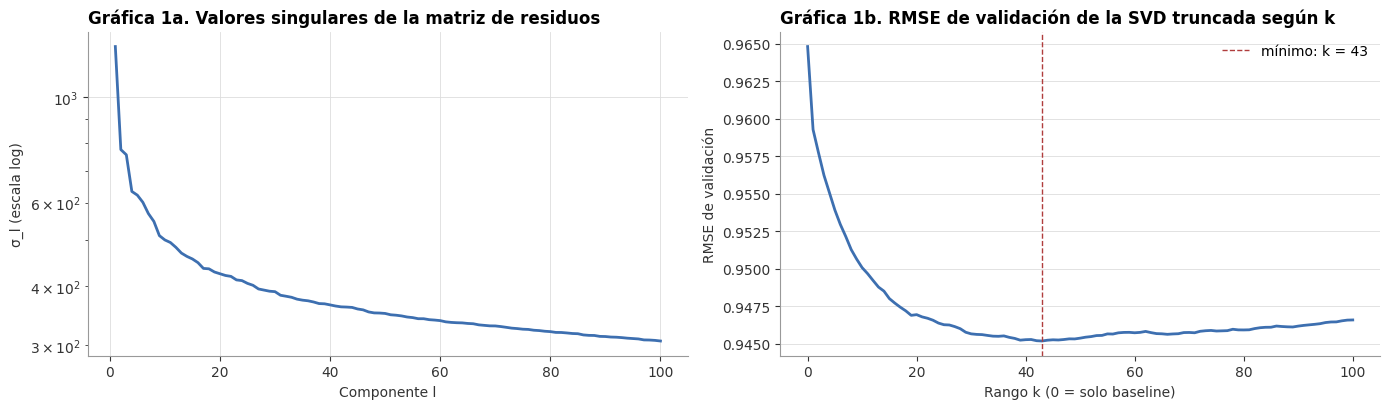

,0,1,2,5,10,20,30,50,75,100
RMSE validación,0.9648,0.9593,0.9577,0.9539,0.9501,0.9469,0.9457,0.9454,0.9458,0.9466


k elegido: 43 | σ_1 / σ_100 = 4.2 | los 100 componentes explican 20.33 % de ‖E‖²_F


In [4]:
# RMSE de validación según k y espectro de valores singulares
KS_SVD = [0, 1, 2, 5, 10, 20, 30, 50, 75, 100]
err2 = np.zeros(101)
for a in range(0, len(val_u), 100_000):
    u, i, r = val_u[a:a + 100_000], val_i[a:a + 100_000], val_r[a:a + 100_000]
    aporte = np.cumsum(U[u] * sigma * Vt[:, i].T, axis=1)
    pred = (mu_v + bu_v[u] + bi_v[i])[:, None] + np.hstack([np.zeros((len(u), 1)), aporte])
    err2 += ((np.clip(pred, 1, 5) - r[:, None]) ** 2).sum(axis=0)
rmse_k = np.sqrt(err2 / len(val_u))
rmse_svd = pd.Series(rmse_k[KS_SVD], index=KS_SVD, name="RMSE validación")
K_SVD = int(np.argmin(rmse_k))
del aporte, pred
gc.collect()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
ax1.plot(np.arange(1, 101), sigma, color=AZUL, linewidth=2)
ax1.set_yscale("log")
estilo_ejes(ax1, "Gráfica 1a. Valores singulares de la matriz de residuos", "Componente l", "σ_l (escala log)", rejilla="both")
ax2.plot(np.arange(101), rmse_k, color=AZUL, linewidth=2)
ax2.axvline(K_SVD, color=ROJO, linestyle="--", linewidth=1, label=f"mínimo: k = {K_SVD}")
ax2.legend()
estilo_ejes(ax2, "Gráfica 1b. RMSE de validación de la SVD truncada según k", "Rango k (0 = solo baseline)",
            "RMSE de validación")
plt.tight_layout()
plt.show()
display(rmse_svd.round(4).to_frame().T)
print(f"k elegido: {K_SVD} | σ_1 / σ_100 = {sigma[0] / sigma[-1]:.1f} | los 100 componentes explican "
      f"{pct(np.sum(sigma.astype(np.float64) ** 2) / energia_E)} de ‖E‖²_F")

In [5]:
# SVD truncada con el k elegido: RMSE en el probe completo y en el de S, y top-N en S
def predecir_svd(u, i):
    return mu_v + bu_v[u] + bi_v[i] + np.einsum("nk,k,nk->n", U[u, :K_SVD], sigma[:K_SVD], Vt[:K_SVD, i].T)


pred_probe = np.clip(por_lotes(predecir_svd, probe_u, probe_m), 1, 5)
pred_S = np.clip(por_lotes(predecir_svd, S_usuarios[S_probe_u], S_peliculas[S_probe_m]), 1, 5)
np.save(RUTA_PREDICCIONES / "svd_truncada_probe.npy", pred_probe.astype(np.float32))
np.save(RUTA_PREDICCIONES / "svd_truncada_S.npy", pred_S.astype(np.float32))

V_S = (sigma[:K_SVD, None] * Vt[:K_SVD][:, S_peliculas])


def puntuar_svd(us):
    g = S_usuarios[us]
    return mu_v + bu_v[g][:, None] + bi_v[S_peliculas][None, :] + U[g, :K_SVD] @ V_S


topn_svd = evaluar_topn(puntuar_svd)
guardar_resultado("SVD truncada (completo)", tipo="predicción y top-N", escala="completo (99 M)",
                  rmse_probe=rmse(pred_probe, probe_r), rmse_probe_S=rmse(pred_S, S_probe_r),
                  segundos_entrenamiento=segundos_svd, configuracion=f"svds sobre residuos del baseline, k = {K_SVD}",
                  **topn_svd)
display(pd.DataFrame({
    "RMSE probe": [referencias["Baseline (completo)"]["rmse_probe"], rmse(pred_probe, probe_r), CINEMATCH_PROBE],
    "RMSE probe S": [referencias["Baseline (completo)"]["rmse_probe_S"], rmse(pred_S, S_probe_r), np.nan],
    **{m: [np.nan, topn_svd[m], np.nan] for m in topn_svd},
}, index=["baseline (completo)", f"SVD truncada k = {K_SVD}", "Cinematch"]).round(4))
del U, Vt, V_S, pred_probe
gc.collect()
ram("2. SVD truncada evaluada")

,RMSE probe,RMSE probe S,P@10,R@10,NDCG@10
baseline (completo),0.9822,0.9753,NaN,NaN,NaN
SVD truncada k = 43,0.9666,0.9581,0.0034,0.0163,0.0105
Cinematch,0.9474,NaN,NaN,NaN,NaN


[RAM] 2. SVD truncada evaluada: proceso 1.96 GB | libre en el sistema 4.96 GB


**Observaciones: SVD truncada**

- **Cálculo.** `svds` con $k = 100$ sobre los 99 millones de residuos tarda unos **3.5 minutos**. El proceso llega a
  **2.15 GB**: la CSR de $R$, la de residuos (que comparte índices con ella) y $U$ de 480,189 × 100 en `float32`.
- **Espectro (Gráfica 1a).** Los valores singulares caen lentamente ($\sigma_1 / \sigma_{100} = 4.2$) y los 100
  componentes explican solo el **20.3 %** de $\lVert E \rVert_F^2$. La mayor parte de los residuos es ruido individual
  que ningún factor común explica.
- **Elección de $k$ (Gráfica 1b).** El RMSE de validación baja de 0.9648 (solo baseline) a **0.9454** con $k = 43$ y
  después sube: los componentes extra ajustan los ceros impuestos y el ruido.
- **Resultado.** RMSE en el probe completo **0.9666**, contra 0.9822 del baseline (−1.6 %), y **0.9581** en el probe
  de S. Queda **2.0 % arriba de Cinematch**: rellenar con ceros el 98.8 % de la matriz limita lo que la SVD puede
  aprender. En top-N (NDCG@10 = 0.0105) hereda el problema del rating predicho visto en el notebook 2.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">FACTORIZACIÓN · PURESVD</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. PureSVD para top-N</span></div>



**Idea (Cremonesi, Koren y Turrin, 2010).** Para **ordenar**, el relleno con ceros deja de ser un defecto. En la matriz
cruda $R$, un 0 significa "no la calificó", y no calificar algo ya es información: la gente califica lo que ve y ve lo
que le interesa. PureSVD factoriza $R \approx U_k \Sigma_k V_k^\top$ y puntúa con la proyección de la fila del usuario
sobre el espacio de las películas:

$$\text{puntaje}_u = r_u\, V_k V_k^\top .$$

No predice un rating, pero aprende a la vez qué películas suele calificar un usuario como $u$ y cuáles le gustan.
Elegimos $k$ con el top-N de validación y después refactorizamos con todo el entrenamiento de S.

In [6]:
# PureSVD en S: elección de k con el top-N de validación y evaluación en el probe
KS_PURE = [10, 25, 50, 100, 150, 200]
t0 = time.perf_counter()
_, s_tr, Vt_tr = svds(S_tr, k=max(KS_PURE), solver="arpack", random_state=SEMILLA)
Vt_tr = Vt_tr[np.argsort(-s_tr)]
val_pure = pd.DataFrame({k: evaluar_topn(lambda us, k=k: (S_tr[us] @ Vt_tr[:k].T) @ Vt_tr[:k],
                                         U_VAL, REL_VAL, S_tr) for k in KS_PURE}).T.rename_axis("k")
K_PURE = int(val_pure[f"NDCG@{K}"].idxmax())
display(val_pure.round(4).T)

_, s_pure, Vt_pure = svds(S_R, k=K_PURE, solver="arpack", random_state=SEMILLA)
Vt_pure = Vt_pure[np.argsort(-s_pure)]
segundos_pure = time.perf_counter() - t0
topn_pure = evaluar_topn(lambda us: (S_R[us] @ Vt_pure.T) @ Vt_pure)
guardar_resultado("PureSVD (S)", tipo="top-N", escala="S", segundos_entrenamiento=segundos_pure,
                  configuracion=f"svds de la matriz cruda con ceros, k = {K_PURE}", **topn_pure)
np.save(RUTA_MODELOS / "puresvd_V_S.npy", Vt_pure.T.astype(np.float32))

display(pd.DataFrame([referencias[m] for m in ["Popularidad", "kNN ítem-ítem (suma de similitudes)"]] +
                     [{"modelo": f"PureSVD k = {K_PURE}", **topn_pure}]).set_index("modelo")[list(topn_pure)].round(4))
print(f"k elegido por NDCG@{K} de validación: {K_PURE} | tiempo total (2 SVD + validación): {segundos_pure:.0f} s")
del Vt_tr
gc.collect()
ram("3. PureSVD")

k,10,25,50,100,150,200
P@10,0.0111,0.0140,0.0153,0.0155,0.0142,0.0129
R@10,0.1106,0.1396,0.1528,0.1552,0.1418,0.1288
NDCG@10,0.0599,0.0749,0.0854,0.0866,0.0784,0.0713


,P@10,R@10,NDCG@10
modelo,,,
Popularidad,0.0053,0.0248,0.0146
kNN ítem-ítem (suma de similitudes),0.0162,0.0780,0.0490
PureSVD k = 100,0.0189,0.0915,0.0554


k elegido por NDCG@10 de validación: 100 | tiempo total (2 SVD + validación): 112 s
[RAM] 3. PureSVD: proceso 2.00 GB | libre en el sistema 4.95 GB


**Observaciones: PureSVD**

- **Elección de $k$.** En el top-N de validación el mejor rango es **$k = 100$** (NDCG@10 = 0.0866). Con más
  componentes empeora: la factorización empieza a reproducir los ratings ya vistos en lugar de generalizar.
- **Es el mejor top-N hasta ahora:** P@10 = **0.0189**, R@10 = **0.0915** y NDCG@10 = **0.0554**. Es **3.8 veces la
  popularidad** y mejor que la suma de similitudes del kNN (0.0162 / 0.0780 / 0.0490).
- **Por qué funciona.** Es la misma SVD de la sección 2 sobre los mismos datos. Solo cambia el relleno: aquí un 0
  significa "no la vio", y eso enseña al modelo qué películas suele **ver** cada tipo de usuario. Es la información
  que el top-N premia y que los modelos de rating, entrenados solo con lo observado, descartan (Cremonesi *et al.*,
  2010). Cuesta **112 s** con dos SVD de S.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">FACTORIZACIÓN · SGD</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. SVD regularizada con sesgos por SGD</span></div>



**Modelo (Koren, Bell y Volinsky, 2009, ec. 5).** Cada usuario $u$ tiene un vector $p_u \in \mathbb{R}^f$ y cada película
un vector $q_i \in \mathbb{R}^f$:

$$\hat r_{ui} = \mu + b_u + b_i + q_i^\top p_u,$$

y los parámetros minimizan el error **solo sobre los ratings observados**, con regularización:

$$\min \sum_{(u,i) \in \text{train}} (r_{ui} - \hat r_{ui})^2 + \lambda \left(\lVert p_u \rVert^2 + \lVert q_i \rVert^2\right)
       + \lambda_b \left(b_u^2 + b_i^2\right).$$

**Descenso de gradiente estocástico.** Para cada rating, con $e_{ui} = r_{ui} - \hat r_{ui}$:

$$b_u \leftarrow b_u + \gamma (e_{ui} - \lambda_b b_u), \quad b_i \leftarrow b_i + \gamma (e_{ui} - \lambda_b b_i), \quad
  p_u \leftarrow p_u + \gamma (e_{ui} q_i - \lambda p_u), \quad q_i \leftarrow q_i + \gamma (e_{ui} p_u - \lambda q_i).$$

**Implementación.**
- **Recorrido aleatorio sin memoria extra.** Una permutación aleatoria de 99 millones de índices `int64` ocuparía
  800 MB. En su lugar, cada época recorre los ratings con un **paso** $a$ coprimo con $n$:
  $k_{t+1} = (k_t + a) \bmod n$. Eso visita cada índice exactamente una vez en un orden muy disperso. El paso y el punto
  de inicio se sortean en cada época.
- **Tasa de aprendizaje.** $\gamma_0 = 0.007$, multiplicada por 0.95 en cada época; $\lambda_b = 0.005$; factores
  iniciales $\mathcal{N}(0, 0.05^2)$ (valores de Koren, 2008).
- **Paro temprano.** Paramos cuando el RMSE de validación sube dos épocas seguidas y nos quedamos con la mejor época.
- **Compilación.** El bucle se compila con `numba`; una época sobre los 99 millones de ratings tarda unos 50 s.

**Rejilla en S.** Elegimos $f \in \{50, 100\}$ y $\lambda \in \{0.015, 0.04\}$ en S (hasta 40 épocas), donde una época tarda segundos. El
mejor modelo de S se evalúa en el probe de S (comparación justa con el kNN) y su configuración se usa para entrenar el
modelo completo.

f =  50, λ = 0.015: mejor época 30, RMSE de validación 0.8916, 338 s


f =  50, λ = 0.04: mejor época 40, RMSE de validación 0.9031, 262 s


f = 100, λ = 0.015: mejor época 26, RMSE de validación 0.8926, 221 s


f = 100, λ = 0.04: mejor época 40, RMSE de validación 0.9012, 322 s


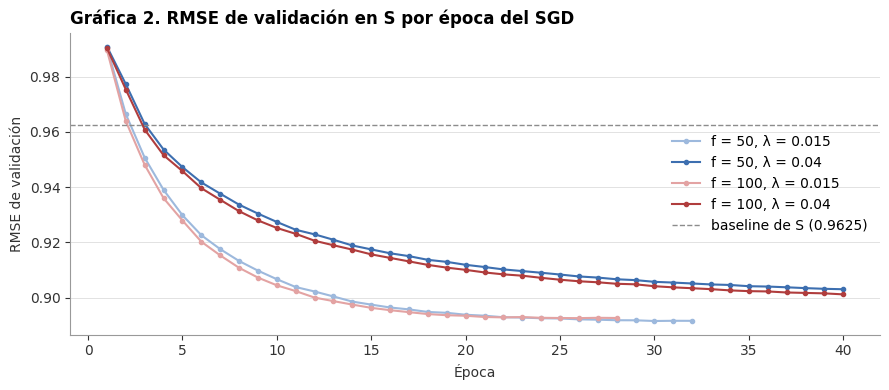

[RAM] 4. rejilla SGD en S: proceso 2.21 GB | libre en el sistema 5.82 GB


In [7]:
# Época de SGD con recorrido por paso coprimo, y entrenamiento con paro temprano por validación
@njit(fastmath=True)
def epoca_sgd(filas, cols, r, usar, mu, bu, bi, P, Q, lr, reg, reg_b, paso, inicio):
    n, f = len(r), P.shape[1]
    k, e2, m = inicio, 0.0, 0
    for _ in range(n):
        k += paso
        if k >= n:
            k -= n
        if not usar[k]:
            continue
        u, i = filas[k], cols[k]
        pred = mu + bu[u] + bi[i]
        for j in range(f):
            pred += P[u, j] * Q[i, j]
        e = r[k] - pred
        e2 += e * e
        m += 1
        bu[u] += lr * (e - reg_b * bu[u])
        bi[i] += lr * (e - reg_b * bi[i])
        for j in range(f):
            pu, qi = P[u, j], Q[i, j]
            P[u, j] += lr * (e * qi - reg * pu)
            Q[i, j] += lr * (e * pu - reg * qi)
    return math.sqrt(e2 / m)


def predecir_mf(modelo, u, i):
    return modelo["mu"] + modelo["bu"][u] + modelo["bi"][i] + np.einsum("nf,nf->n", modelo["P"][u], modelo["Q"][i])


def entrenar_sgd(X, filas, usar, val, f, reg, lr=0.007, decaimiento=0.95, reg_b=0.005, max_epocas=40, paciencia=2):
    rng = np.random.default_rng(SEMILLA)
    n = X.nnz
    mu = np.float32(np.sum(X.data, where=usar, dtype=np.float64) / usar.sum())
    modelo = {"mu": mu, "bu": np.zeros(X.shape[0], np.float32), "bi": np.zeros(X.shape[1], np.float32),
              "P": (rng.standard_normal((X.shape[0], f)) * 0.05).astype(np.float32),
              "Q": (rng.standard_normal((X.shape[1], f)) * 0.05).astype(np.float32)}
    mejor, historia, sin_mejora, t0 = None, [], 0, time.perf_counter()
    for epoca in range(1, max_epocas + 1):
        paso = int(rng.integers(n // 3, 2 * n // 3))
        while math.gcd(paso, n) != 1:
            paso += 1
        rmse_train = epoca_sgd(filas, X.indices, X.data, usar, mu, modelo["bu"], modelo["bi"], modelo["P"], modelo["Q"],
                               np.float32(lr * decaimiento ** (epoca - 1)), np.float32(reg), np.float32(reg_b),
                               paso, int(rng.integers(n)))
        historia.append({"época": epoca, "RMSE train": rmse_train, "RMSE validación": rmse(por_lotes(lambda u, i: predecir_mf(modelo, u, i), *val[:2]), val[2])})
        if mejor is None or historia[-1]["RMSE validación"] < mejor[0]:
            mejor, sin_mejora = (historia[-1]["RMSE validación"], epoca, {c: np.copy(v) for c, v in modelo.items()}), 0
        else:
            sin_mejora += 1
            if sin_mejora == paciencia:
                break
    return {**mejor[2], "epoca": mejor[1], "rmse_val": mejor[0], "historia": pd.DataFrame(historia).set_index("época"),
            "segundos": time.perf_counter() - t0}


# Rejilla f × λ en S, sin la validación
filas_S = np.repeat(np.arange(n_S_usr, dtype=np.int32), np.diff(S_R.indptr))
val_S = (S_val_u, S_val_i, S_val_r)
modelos_S = {}
for f in [50, 100]:
    for reg in [0.015, 0.04]:
        modelos_S[(f, reg)] = entrenar_sgd(S_R, filas_S, ~S_es_val, val_S, f, reg)
        m = modelos_S[(f, reg)]
        print(f"f = {f:>3}, λ = {reg}: mejor época {m['epoca']:>2}, RMSE de validación {m['rmse_val']:.4f}, {m['segundos']:.0f} s")
F_SGD, REG_SGD = min(modelos_S, key=lambda c: modelos_S[c]["rmse_val"])
sgd_S = modelos_S[(F_SGD, REG_SGD)]

fig, ax = plt.subplots(figsize=(9, 4))
colores = {(50, 0.015): "#9DB9DD", (50, 0.04): AZUL, (100, 0.015): "#E3A3A3", (100, 0.04): ROJO}
for c, m in modelos_S.items():
    ax.plot(m["historia"].index, m["historia"]["RMSE validación"], color=colores[c], marker="o", markersize=3,
            label=f"f = {c[0]}, λ = {c[1]}")
ax.axhline(0.9625, color=GRIS, linestyle="--", linewidth=1, label="baseline de S (0.9625)")
ax.legend()
estilo_ejes(ax, "Gráfica 2. RMSE de validación en S por época del SGD", "Época", "RMSE de validación")
plt.tight_layout()
plt.show()
ram("4. rejilla SGD en S")

In [8]:
# Mejor modelo de S: RMSE y top-N en el probe de S
pred_sgd_S = np.clip(predecir_mf(sgd_S, S_probe_u, S_probe_m), 1, 5)
pred_sgd_S[sin_train_S[S_probe_u]] = S_base_probe[sin_train_S[S_probe_u]]  # respaldo: usuarios sin ratings en S
np.save(RUTA_PREDICCIONES / "svd_sgd_S.npy", pred_sgd_S.astype(np.float32))
np.savez(RUTA_MODELOS / "svd_sgd_S.npz", **{c: sgd_S[c] for c in ["mu", "bu", "bi", "P", "Q"]})
topn_sgd_S = evaluar_topn(lambda us: sgd_S["mu"] + sgd_S["bu"][us][:, None] + sgd_S["bi"][None, :] + sgd_S["P"][us] @ sgd_S["Q"].T)
guardar_resultado("SVD-SGD (S)", tipo="predicción y top-N", escala="S", rmse_probe_S=rmse(pred_sgd_S, S_probe_r),
                  segundos_entrenamiento=sgd_S["segundos"],
                  configuracion=f"f = {F_SGD}, λ = {REG_SGD}, {sgd_S['epoca']} épocas", **topn_sgd_S)
display(pd.DataFrame({
    "RMSE probe S": [referencias["Baseline (S)"]["rmse_probe_S"], referencias["kNN ítem-ítem"]["rmse_probe_S"],
                     rmse(pred_sgd_S, S_probe_r)],
    **{m: [referencias["Baseline (S)"][m], referencias["kNN ítem-ítem"][m], topn_sgd_S[m]] for m in topn_sgd_S},
}, index=["baseline de S", "kNN ítem-ítem (rating predicho)", f"SVD-SGD f = {F_SGD}, λ = {REG_SGD}"]).round(4))
del modelos_S, filas_S
gc.collect()
ram("4. SGD en S evaluado")

,RMSE probe S,P@10,R@10,NDCG@10
baseline de S,0.9760,0.0021,0.0097,0.0066
kNN ítem-ítem (rating predicho),0.9312,0.0036,0.0181,0.0109
"SVD-SGD f = 50, λ = 0.015",0.9106,0.0048,0.0221,0.0138


[RAM] 4. SGD en S evaluado: proceso 2.07 GB | libre en el sistema 5.94 GB


**Modelo completo.** Entrenamos con los 99 millones de ratings, sin la validación y con la configuración elegida en S,
y lo evaluamos en el probe completo, que es la comparación directa con Cinematch.

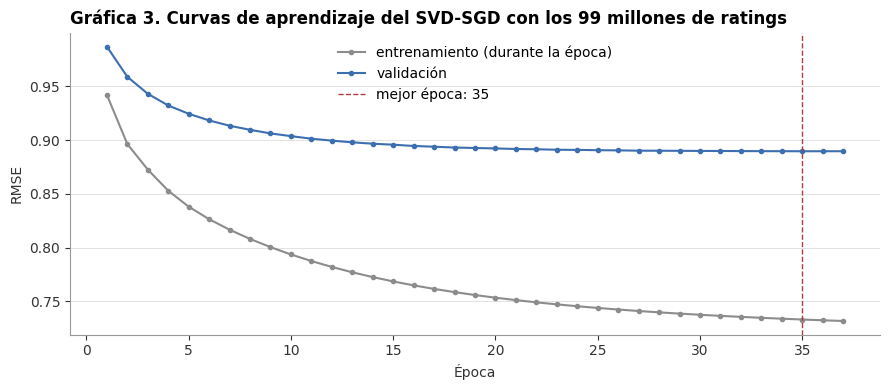

,RMSE probe,vs. Cinematch
baseline (completo),0.9822,+3.68 %
SVD truncada (k = 43),0.9666,+2.03 %
"SVD-SGD (f = 50, λ = 0.015)",0.9130,-3.64 %
Cinematch,0.9474,+0.00 %


Entrenamiento: 27.2 min, 37 épocas (44 s por época) | RMSE probe S del modelo completo: 0.9043 | P: 96.0 MB
[RAM] 4. SGD completo: proceso 797.2 MB | libre en el sistema 7.27 GB


In [9]:
# SVD-SGD con los 99 millones de ratings y la configuración elegida en S
sgd = entrenar_sgd(R, filas_R, ~es_val, (val_u, val_i, val_r), F_SGD, REG_SGD, max_epocas=40)
pred_sgd = np.clip(por_lotes(lambda u, i: predecir_mf(sgd, u, i), probe_u, probe_m), 1, 5)
pred_sgd_en_S = np.clip(por_lotes(lambda u, i: predecir_mf(sgd, u, i), S_usuarios[S_probe_u], S_peliculas[S_probe_m]), 1, 5)
np.save(RUTA_PREDICCIONES / "svd_sgd_probe.npy", pred_sgd.astype(np.float32))
np.save(RUTA_PREDICCIONES / "svd_sgd_completo_S.npy", pred_sgd_en_S.astype(np.float32))
np.savez(RUTA_MODELOS / "svd_sgd_completo.npz", mu=sgd["mu"], bu=sgd["bu"], bi=sgd["bi"], Q=sgd["Q"])

Q_S = sgd["Q"][S_peliculas]
topn_sgd = evaluar_topn(lambda us: sgd["mu"] + sgd["bu"][S_usuarios[us]][:, None] + sgd["bi"][S_peliculas][None, :]
                        + sgd["P"][S_usuarios[us]] @ Q_S.T)
guardar_resultado("SVD-SGD (completo)", tipo="predicción y top-N", escala="completo (99 M)",
                  rmse_probe=rmse(pred_sgd, probe_r), rmse_probe_S=rmse(pred_sgd_en_S, S_probe_r),
                  segundos_entrenamiento=sgd["segundos"],
                  configuracion=f"f = {F_SGD}, λ = {REG_SGD}, {sgd['epoca']} épocas", **topn_sgd)

fig, ax = plt.subplots(figsize=(9, 4))
h = sgd["historia"]
ax.plot(h.index, h["RMSE train"], color=GRIS, marker="o", markersize=3, label="entrenamiento (durante la época)")
ax.plot(h.index, h["RMSE validación"], color=AZUL, marker="o", markersize=3, label="validación")
ax.axvline(sgd["epoca"], color=ROJO, linestyle="--", linewidth=1, label=f"mejor época: {sgd['epoca']}")
ax.legend()
estilo_ejes(ax, "Gráfica 3. Curvas de aprendizaje del SVD-SGD con los 99 millones de ratings", "Época", "RMSE")
plt.tight_layout()
plt.show()

rmse_sgd = rmse(pred_sgd, probe_r)
tabla = pd.DataFrame({"RMSE probe": {
    "baseline (completo)": referencias["Baseline (completo)"]["rmse_probe"],
    f"SVD truncada (k = {K_SVD})": json.load(open(RUTA_RESULTADOS / "SVD truncada (completo).json", encoding="utf-8"))["rmse_probe"],
    f"SVD-SGD (f = {F_SGD}, λ = {REG_SGD})": rmse_sgd, "Cinematch": CINEMATCH_PROBE}})
tabla["vs. Cinematch"] = (tabla["RMSE probe"] / CINEMATCH_PROBE - 1).map(lambda v: f"{100 * v:+.2f} %")
display(tabla.round(4))
print(f"Entrenamiento: {sgd['segundos'] / 60:.1f} min, {len(h)} épocas ({sgd['segundos'] / len(h):.0f} s por época) | "
      f"RMSE probe S del modelo completo: {rmse(pred_sgd_en_S, S_probe_r):.4f} | P: {tamano(sgd['P'].nbytes)}")
del sgd["P"], R, filas_R, es_val
gc.collect()
ram("4. SGD completo")

**Observaciones: SVD con sesgos por SGD**

- **Rejilla en S (Gráfica 2).** La mejor configuración es **$f = 50$, $\lambda = 0.015$**, con RMSE de validación
  **0.8916** en la época 30.
  - $f = 100$ no mejora (0.8926) y alcanza su mínimo antes (época 26): con 19 millones de ratings, 100 factores
    empiezan a sobreajustar.
  - Con $\lambda = 0.04$ el modelo converge más lento y llega a 0.90–0.91 en 40 épocas.
- **Modelo de S.** RMSE en el probe de S **0.9106**: 6.7 % mejor que el baseline de S y 2.2 % mejor que el kNN
  ítem-ítem (0.9312), con el mismo entrenamiento.
- **Modelo completo (Gráfica 3).** Con los 99 millones de ratings, la validación mejora hasta la **época 35** y el
  RMSE de entrenamiento sigue bajando: después de ese punto el modelo sobreajusta. El entrenamiento tarda **27 min**
  (44 s por época).
- **RMSE en el probe completo: 0.9130, 3.6 % mejor que Cinematch (0.9474).** En el probe de S da 0.9043. Con 50
  factores y un SGD de unas 40 líneas, implementado por nosotros, superamos al sistema de Netflix. Es del orden de lo que
  Koren, Bell y Volinsky (2009) reportan para la SVD con sesgos (entre 0.90 y 0.91).
- **Top-N.** Como modelo de rating, ordena casi igual que la popularidad (NDCG@10 de 0.0138 en S y 0.0149 el completo).

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">FACTORIZACIÓN · NMF</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. NMF con máscara</span></div>



**Modelo.** Buscamos $W \ge 0$ (usuarios × $k$) y $H \ge 0$ (películas × $k$) con $\hat r_{ui} = w_u^\top h_i$,
minimizando el error **solo sobre los ratings observados** $\Omega$ (la máscara), con regularización:

$$\min_{W, H \ge 0} \sum_{(u,i) \in \Omega} (r_{ui} - w_u^\top h_i)^2 + \lambda \left(\lVert W \rVert_F^2 + \lVert H \rVert_F^2\right).$$

**Reglas multiplicativas** (Lee y Seung, 2001, con la máscara):

$$w_{uj} \leftarrow w_{uj}\, \frac{\sum_{i \in \Omega_u} r_{ui}\, h_{ij}}{\sum_{i \in \Omega_u} \hat r_{ui}\, h_{ij} + \lambda w_{uj}},
  \qquad h_{ij} \leftarrow h_{ij}\, \frac{\sum_{u \in \Omega_i} r_{ui}\, w_{uj}}{\sum_{u \in \Omega_i} \hat r_{ui}\, w_{uj} + \lambda h_{ij}}.$$

Al multiplicar por cocientes de cantidades positivas, los factores nunca se vuelven negativos y el error no aumenta.
Las dos reglas son la misma función aplicada a las filas de la CSR (usuarios) y a las de la CSC (películas),
paralelizada con `numba`. Trabajamos con los ratings **crudos**: la no negatividad impide centrarlos. Por eso los
factores tienen que reconstruir también la media y los sesgos, que el SGD modela aparte.

k = 10, λ =  5.0: mejor iteración 300, RMSE de validación 0.9351, 202 s


k = 10, λ = 25.0: mejor iteración 300, RMSE de validación 0.9713, 200 s


k = 20, λ =  5.0: mejor iteración 300, RMSE de validación 0.9510, 299 s


k = 20, λ = 25.0: mejor iteración 300, RMSE de validación 0.9781, 298 s


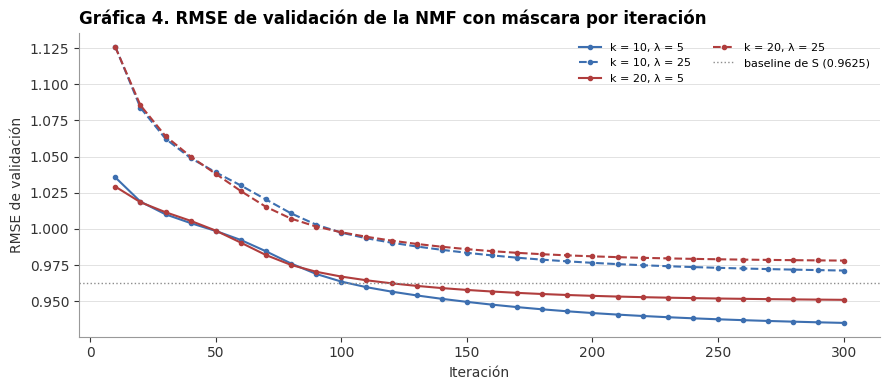

[RAM] 5. rejilla NMF: proceso 816.1 MB | libre en el sistema 7.27 GB


In [10]:
# NMF con máscara por reglas multiplicativas: rejilla k × λ en S con validación
@njit(parallel=True)
def actualizar_nmf(indptr, indices, datos, A, B, lam):
    # Actualiza las filas de A con los ratings de cada fila (CSR para W, CSC para H)
    k = A.shape[1]
    for u in prange(A.shape[0]):
        num, den = np.zeros(k), np.zeros(k)
        for p in range(indptr[u], indptr[u + 1]):
            i = indices[p]
            pred = 0.0
            for j in range(k):
                pred += A[u, j] * B[i, j]
            for j in range(k):
                num[j] += datos[p] * B[i, j]
                den[j] += pred * B[i, j]
        for j in range(k):
            A[u, j] *= num[j] / (den[j] + lam * A[u, j] + 1e-9)


def entrenar_nmf(X, k, lam, val, max_iter=300, cada=10, paciencia=2):
    rng = np.random.default_rng(SEMILLA)
    Xc = X.tocsc()
    escala = np.sqrt(4 * X.data.mean() / k)  # E[w·h] ≈ rating medio al inicio
    W = (rng.random((X.shape[0], k)) * escala).astype(np.float64)
    H = (rng.random((X.shape[1], k)) * escala).astype(np.float64)
    mejor, historia, sin_mejora, t0 = None, [], 0, time.perf_counter()
    for it in range(1, max_iter + 1):
        actualizar_nmf(X.indptr, X.indices, X.data, W, H, lam)
        actualizar_nmf(Xc.indptr, Xc.indices, Xc.data, H, W, lam)
        if it % cada == 0:
            historia.append({"iteración": it, "RMSE validación": rmse(np.einsum("nk,nk->n", W[val[0]], H[val[1]]), val[2])})
            if mejor is None or historia[-1]["RMSE validación"] < mejor[0]:
                mejor, sin_mejora = (historia[-1]["RMSE validación"], it, W.copy(), H.copy()), 0
            else:
                sin_mejora += 1
                if sin_mejora == paciencia:
                    break
    return {"W": mejor[2], "H": mejor[3], "iteracion": mejor[1], "rmse_val": mejor[0],
            "historia": pd.DataFrame(historia).set_index("iteración"), "segundos": time.perf_counter() - t0}


modelos_nmf = {}
for k in [10, 20]:
    for lam in [5.0, 25.0]:
        modelos_nmf[(k, lam)] = entrenar_nmf(S_tr, k, lam, val_S)
        m = modelos_nmf[(k, lam)]
        print(f"k = {k:>2}, λ = {lam:>4}: mejor iteración {m['iteracion']:>3}, RMSE de validación {m['rmse_val']:.4f}, "
              f"{m['segundos']:.0f} s")
K_NMF, LAM_NMF = min(modelos_nmf, key=lambda c: modelos_nmf[c]["rmse_val"])
nmf = modelos_nmf[(K_NMF, LAM_NMF)]

fig, ax = plt.subplots(figsize=(9, 4))
for (k, lam), m in modelos_nmf.items():
    ax.plot(m["historia"].index, m["historia"]["RMSE validación"], marker="o", markersize=3,
            color=AZUL if k == 10 else ROJO, linestyle="-" if lam == 5.0 else "--",
            label=f"k = {k}, λ = {lam:g}")
ax.axhline(0.9625, color=GRIS, linestyle=":", linewidth=1, label="baseline de S (0.9625)")
ax.legend(ncol=2, fontsize=8)
estilo_ejes(ax, "Gráfica 4. RMSE de validación de la NMF con máscara por iteración", "Iteración", "RMSE de validación")
plt.tight_layout()
plt.show()
ram("5. rejilla NMF")

In [11]:
# NMF elegida: RMSE y top-N en el probe de S, con respaldo del baseline para usuarios sin ratings en S
pred_nmf = np.clip(np.einsum("nk,nk->n", nmf["W"][S_probe_u], nmf["H"][S_probe_m]), 1, 5)
pred_nmf[sin_train_S[S_probe_u]] = S_base_probe[sin_train_S[S_probe_u]]
np.save(RUTA_PREDICCIONES / "nmf_S.npy", pred_nmf.astype(np.float32))
np.savez(RUTA_MODELOS / "nmf_S.npz", W=nmf["W"].astype(np.float32), H=nmf["H"].astype(np.float32))
topn_nmf = evaluar_topn(lambda us: nmf["W"][us] @ nmf["H"].T)
guardar_resultado("NMF con máscara (S)", tipo="predicción y top-N", escala="S", rmse_probe_S=rmse(pred_nmf, S_probe_r),
                  segundos_entrenamiento=nmf["segundos"],
                  configuracion=f"k = {K_NMF}, λ = {LAM_NMF:g}, {nmf['iteracion']} iteraciones", **topn_nmf)
display(pd.DataFrame({
    "RMSE probe S": [referencias["Baseline (S)"]["rmse_probe_S"], rmse(pred_sgd_S, S_probe_r), rmse(pred_nmf, S_probe_r)],
    **{m: [referencias["Baseline (S)"][m], topn_sgd_S[m], topn_nmf[m]] for m in topn_nmf},
}, index=["baseline de S", f"SVD-SGD (S)", f"NMF k = {K_NMF}, λ = {LAM_NMF:g}"]).round(4))

# Interpretación: películas con mayor peso en cada uno de los primeros factores de H, normalizados por columna
peliculas = pd.read_parquet(RUTA_PROCESADOS / "peliculas.parquet")
H_norm = nmf["H"] / nmf["H"].sum(axis=0)
populares = np.diff(S_R.tocsc().indptr) >= 2000
factores = pd.DataFrame({f"factor {j + 1}": peliculas.loc[S_peliculas[np.flatnonzero(populares)[np.argsort(-H_norm[populares, j])[:6]]], "title"].to_numpy()
                         for j in range(min(K_NMF, 6))}, index=range(1, 7))
display(factores)
del modelos_nmf
gc.collect()
ram("5. NMF")

,RMSE probe S,P@10,R@10,NDCG@10
baseline de S,0.9760,0.0021,0.0097,0.0066
SVD-SGD (S),0.9106,0.0048,0.0221,0.0138
"NMF k = 10, λ = 5",0.9470,0.0054,0.0244,0.0154


,factor 1,factor 2,factor 3,factor 4,factor 5,factor 6
1,Friends: Season 3,The Office: Series 1,Dawn of the Dead,Armageddon,Star Trek: The Next Generation: Season 3,De-Lovely
2,Friends: Season 2,The Royal Tenenbaums,8 1/2,The Day After Tomorrow,Stargate SG-1: Season 1,Angels in America
3,The Best of Friends: Season 2,Punch-Drunk Love,Night of the Living Dead,Independence Day,Star Trek: The Next Generation: Season 1,The Corporation
4,The Best of Friends: Vol. 1,I Heart Huckabees,The Treasure of the Sierra Madre,Pearl Harbor,Star Trek IV: The Voyage Home,Born Into Brothels
5,Friends: The Series Finale,The Life Aquatic with Steve Zissou,The Texas Chainsaw Massacre,Gone in 60 Seconds,The Sound of Music,A Very Long Engagement
6,Friends: Season 1,Eternal Sunshine of the Spotless Mind,The Big Sleep,Swordfish,The King and I,Real Women Have Curves


[RAM] 5. NMF: proceso 811.6 MB | libre en el sistema 7.27 GB


**Observaciones: NMF con máscara**

- **Rejilla (Gráfica 4).** La mejor configuración es **$k = 10$, $\lambda = 5$**, con RMSE de validación **0.9351**.
  - Todas las configuraciones siguen mejorando en la iteración 300: las reglas multiplicativas convergen lento
    (~0.7 s por iteración).
  - Con $k = 20$ el resultado es peor (0.9510), y con $\lambda = 25$ la regularización encoge demasiado los factores.
- **Resultado.** RMSE en el probe de S **0.9470**: mejor que el baseline (0.9760), pero lejos del SGD (0.9106). La
  NMF tiene que reconstruir con productos de factores no negativos también la media y los sesgos, que el SGD modela
  aparte, y eso le gasta capacidad. En top-N queda casi igual a la popularidad (NDCG@10 = 0.0154).
- **Su ventaja es la interpretación.** Al no haber cancelaciones entre signos, cada factor es una "parte" aditiva de
  los gustos, y las películas con más peso forman grupos claros:
  - factor 1: *Friends* (sitcom);
  - factor 2: comedia independiente y excéntrica (*The Royal Tenenbaums*, *The Office*, *Eternal Sunshine*);
  - factor 3: terror y cine clásico (*Dawn of the Dead*, *8 1/2*, *The Big Sleep*);
  - factor 4: superproducciones de acción (*Armageddon*, *Independence Day*, *Pearl Harbor*);
  - factor 5: ciencia ficción televisiva y musicales clásicos (*Star Trek*, *Stargate*, *The Sound of Music*);
  - factor 6: documental y drama independiente (*The Corporation*, *Born Into Brothels*, *Angels in America*).

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">FACTORIZACIÓN · VISUALIZACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Visualización de los factores latentes</span></div>



Proyectamos a 2 dimensiones los vectores $q_i$ del SVD-SGD completo de las **2,000 películas con más ratings** (las
demás tienen factores ruidosos):

- con **PCA**, que conserva las direcciones de mayor varianza y permite interpretar los ejes;
- con **t-SNE** (perplejidad 30, inicializado con PCA, semilla 42), que conserva los vecindarios locales y deja ver
  grupos, aunque sus ejes y distancias globales no significan nada.

Coloreamos por año de estreno y anotamos algunos títulos conocidos.

PCA + t-SNE: 19 s | varianza explicada por los 10 primeros componentes: 10.0 %, 6.0 %, 4.4 %, 4.3 %, 4.0 %, 3.5 %, 3.3 %, 3.1 %, 2.7 %, 2.5 %


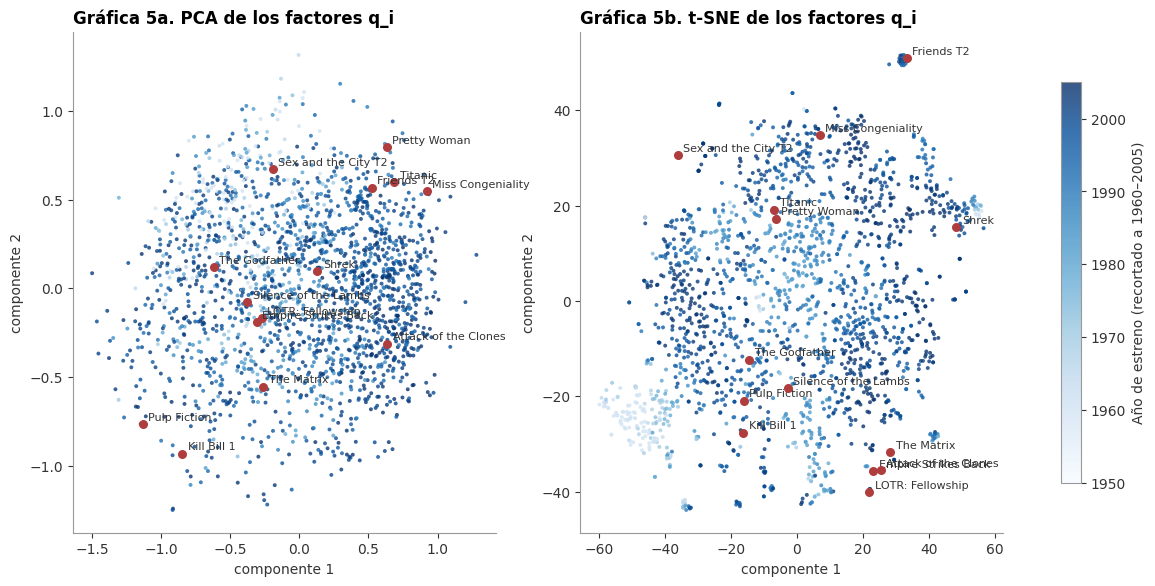

,PC1 negativo,PC1 positivo,PC2 negativo,PC2 positivo
1,Lost in Translation,Pearl Harbor,Fear and Loathing in Las Vegas,The Sound of Music
2,Being John Malkovich,Coyote Ugly,Sin City,Funny Girl
3,The Royal Tenenbaums,Maid in Manhattan,Half Baked,Steel Magnolias
4,Adaptation,Armageddon,Jay and Silent Bob Strike Back,Miracle on 34th Street
5,Eternal Sunshine of the Spotless Mind,Enough,Jackass: The Movie,The Way We Were
6,Rushmore,The Wedding Planner,Super Troopers,On Golden Pond
7,Brazil,National Treasure,From Dusk Till Dawn,The King and I
8,Punch-Drunk Love,Snow Dogs,Old School,Sleepless in Seattle


Correlación de PC1 y PC2 con el año: 0.286, -0.266 | con el sesgo b_i: -0.320, 0.370
[RAM] 6. visualización: proceso 799.8 MB | libre en el sistema 7.28 GB


In [12]:
# PCA y t-SNE de los factores de las 2,000 películas más calificadas
top = np.argsort(-peliculas["n_train"].to_numpy())[:2000]
Q_top = sgd["Q"][top]
t0 = time.perf_counter()
pca = PCA(n_components=10, random_state=SEMILLA).fit(Q_top)
Z_pca = pca.transform(Q_top)[:, :2]
Z_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEMILLA).fit_transform(Q_top)
print(f"PCA + t-SNE: {time.perf_counter() - t0:.0f} s | varianza explicada por los 10 primeros componentes: "
      + ", ".join(pct(v, 1) for v in pca.explained_variance_ratio_))

anio = peliculas.loc[top, "year"].astype(float).fillna(peliculas["year"].median()).clip(1960, 2005).to_numpy()
anotar = {2451: "LOTR: Fellowship", 11063: "Pulp Fiction", 15069: "Sex and the City T2", 14620: "Shrek",
          12292: "The Godfather", 5581: "Empire Strikes Back", 14690: "The Matrix", 16878: "Titanic",
          14453: "Kill Bill 1", 5316: "Miss Congeniality", 6286: "Pretty Woman", 1876: "Friends T2", 3455: "Lost T1",
          2861: "Silence of the Lambs", 8686: "Attack of the Clones"}
pos_en_top = {m: np.flatnonzero(top == m)[0] for m in anotar if m in set(top)}

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, Z, titulo in [(axes[0], Z_pca, "Gráfica 5a. PCA de los factores q_i"), (axes[1], Z_tsne, "Gráfica 5b. t-SNE de los factores q_i")]:
    puntos = ax.scatter(Z[:, 0], Z[:, 1], c=anio, cmap="Blues", s=8, alpha=0.8, linewidths=0, vmin=1950)
    for m, p in pos_en_top.items():
        ax.scatter(*Z[p], s=30, color=ROJO, zorder=3)
        ax.annotate(anotar[m], Z[p], xytext=(4, 3), textcoords="offset points", fontsize=8, color=TINTA)
    estilo_ejes(ax, titulo, "componente 1", "componente 2", rejilla=None)
fig.colorbar(puntos, ax=axes, shrink=0.8, label="Año de estreno (recortado a 1960–2005)")
plt.show()

# Interpretación de los dos primeros componentes de PCA: películas en cada extremo
extremos = {}
for c in range(2):
    orden = np.argsort(Z_pca[:, c])
    extremos[f"PC{c + 1} negativo"] = peliculas.loc[top[orden[:8]], "title"].to_numpy()
    extremos[f"PC{c + 1} positivo"] = peliculas.loc[top[orden[::-1][:8]], "title"].to_numpy()
display(pd.DataFrame(extremos, index=range(1, 9)))
print(f"Correlación de PC1 y PC2 con el año: {np.corrcoef(Z_pca[:, 0], anio)[0, 1]:.3f}, {np.corrcoef(Z_pca[:, 1], anio)[0, 1]:.3f} | "
      f"con el sesgo b_i: {np.corrcoef(Z_pca[:, 0], sgd['bi'][top])[0, 1]:.3f}, {np.corrcoef(Z_pca[:, 1], sgd['bi'][top])[0, 1]:.3f}")
ram("6. visualización")

**Observaciones: PCA y t-SNE**

- **PCA (Gráfica 5a).** Los dos primeros componentes explican apenas el **10.0 %** y el **6.0 %** de la varianza de los
  $q_i$: los 50 factores reparten la información y ninguna dirección domina. Aun así, los ejes se leen:
  - **PC1** opone cine de autor (*Lost in Translation*, *Being John Malkovich*, *Adaptation*, *Brazil*) a cine
    comercial (*Pearl Harbor*, *Coyote Ugly*, *Armageddon*, *The Wedding Planner*);
  - **PC2** opone comedia gamberra y cine de culto masculino (*Jackass*, *Half Baked*, *Super Troopers*, *Sin City*)
    a musicales y dramas románticos clásicos (*The Sound of Music*, *Funny Girl*, *Steel Magnolias*).
- **Color por año.** La correlación de los componentes con el año es moderada (0.29 y −0.27): la época influye, pero
  no es lo que más separa los gustos.
- **t-SNE (Gráfica 5b).** Conserva vecindarios y muestra grupos que el PCA mezcla:
  - una isla de **películas antiguas** (anteriores a 1970, en tonos claros, a la izquierda);
  - **cúmulos compactos de series de televisión**, como las temporadas de *Friends* arriba a la derecha;
  - las **sagas** juntas: *Star Wars* y *El Señor de los Anillos* abajo, cerca de *The Matrix*.

  *Pulp Fiction* y *Kill Bill* quedan en la misma zona, y *Pretty Woman*, *Titanic* y *Miss Congeniality* en otra.

### 6.1 Interpretación de los factores de la SVD

Los factores del SGD no tienen un orden: cualquier rotación de $P$ y $Q$ da el mismo producto. Los de la **SVD
truncada** sí: el factor $l$ es la dirección que más varianza explica de los residuos después de las $l-1$ anteriores.
Como en la figura 3 de Koren, Bell y Volinsky (2009), para cada uno de los primeros 5 factores ($\sigma_l v_{il}$)
listamos las 10 películas con valor más alto y más bajo entre las 2,000 más calificadas. Después los comparamos con los
componentes del PCA de la sección 6 y con variables observables: año, sesgo $b_i$ y popularidad. El signo de cada
factor es arbitrario; lo que importa es qué separa.

In [13]:
# Las 10 películas con valor más alto y más bajo en cada uno de los 5 primeros factores de la SVD truncada
svd = np.load(RUTA_MODELOS / "svd_truncada.npz")
V5 = (svd["Vt"][:5, top] * svd["sigma"][:5, None]).T  # 2,000 películas × 5 factores
nombre = lambda m: f"{peliculas.loc[m, 'title']} ({peliculas.loc[m, 'year']})"
for l in range(5):
    orden = np.argsort(V5[:, l])
    display(pd.DataFrame({"valor más alto": [nombre(top[p]) for p in orden[::-1][:10]],
                          "valor más bajo": [nombre(top[p]) for p in orden[:10]]},
                         index=range(1, 11)).rename_axis(f"Factor {l + 1} (σ = {svd['sigma'][l]:,.0f})"))

,valor más alto,valor más bajo
"Factor 1 (σ = 1,281)",,
1,Pearl Harbor (2001),The Royal Tenenbaums (2001)
2,Miss Congeniality (2000),Lost in Translation (2003)
3,Armageddon (1998),Pulp Fiction (1994)
4,Independence Day (1996),American Beauty (1999)
5,The Patriot (2000),Eternal Sunshine of the Spotless Mind (2004)
6,The Day After Tomorrow (2004),Memento (2000)
7,Sweet Home Alabama (2002),Adaptation (2002)
8,The Wedding Planner (2001),Being John Malkovich (1999)
9,Twister (1996),Kill Bill: Vol. 1 (2003)


,valor más alto,valor más bajo
Factor 2 (σ = 776),,
1,Miss Congeniality (2000),Independence Day (1996)
2,Sister Act (1992),The Matrix (1999)
3,Pretty Woman (1990),American Pie (1999)
4,Dirty Dancing (1987),The Matrix: Reloaded (2003)
5,Steel Magnolias (1989),Kill Bill: Vol. 1 (2003)
6,Sweet Home Alabama (2002),The Waterboy (1998)
7,The Wedding Planner (2001),Austin Powers: The Spy Who Shagged Me (1999)
8,Ghost (1990),Anchorman: The Legend of Ron Burgundy (2004)
9,Stepmom (1998),Happy Gilmore (1996)


,valor más alto,valor más bajo
Factor 3 (σ = 757),,
1,Forrest Gump (1994),The Royal Tenenbaums (2001)
2,Pretty Woman (1990),The Day After Tomorrow (2004)
3,Top Gun (1986),The League of Extraordinary Gentlemen (2003)
4,Braveheart (1995),Lost in Translation (2003)
5,Titanic (1997),The Fast and the Furious (2001)
6,Gladiator (2000),Mr. Deeds (2002)
7,Big (1988),Van Helsing (2004)
8,Saving Private Ryan (1998),S.W.A.T. (2003)
9,Ghost (1990),Gone in 60 Seconds (2000)


,valor más alto,valor más bajo
Factor 4 (σ = 633),,
1,The Patriot (2000),Tommy Boy (1995)
2,The Day After Tomorrow (2004),Dirty Dancing (1987)
3,Lord of the Rings: The Fellowship of the Ring (2001),Coming to America (1988)
4,Lord of the Rings: The Two Towers (2002),National Lampoon's Vacation (1983)
5,Pearl Harbor (2001),The Waterboy (1998)
6,The Last Samurai (2003),Ace Ventura: Pet Detective (1994)
7,Troy (2004),Spaceballs (1987)
8,Master and Commander: The Far Side of the World (2003),Happy Gilmore (1996)
9,Lord of the Rings: The Return of the King (2003),Pretty Woman (1990)


,valor más alto,valor más bajo
Factor 5 (σ = 622),,
1,Miss Congeniality (2000),The Patriot (2000)
2,Sweet Home Alabama (2002),Men of Honor (2000)
3,Pirates of the Caribbean: The Curse of the Black Pearl (2003),Apocalypse Now (1979)
4,Kill Bill: Vol. 1 (2003),Jaws (1975)
5,How to Lose a Guy in 10 Days (2003),Con Air (1997)
6,The Royal Tenenbaums (2001),The General's Daughter (1999)
7,Lost in Translation (2003),Rocky (1976)
8,Napoleon Dynamite (2004),The Graduate (1967)
9,My Big Fat Greek Wedding (2002),Taxi Driver (1976)


,factor 1,factor 2,factor 3,factor 4,factor 5
PC1 (SGD),0.756,-0.072,-0.099,-0.041,0.060
PC2 (SGD),0.094,0.669,0.270,0.167,-0.067
año,0.181,-0.118,-0.232,0.260,0.364
sesgo b_i,-0.278,0.074,0.477,0.087,-0.069
log10 ratings,0.154,-0.163,0.335,0.218,0.321


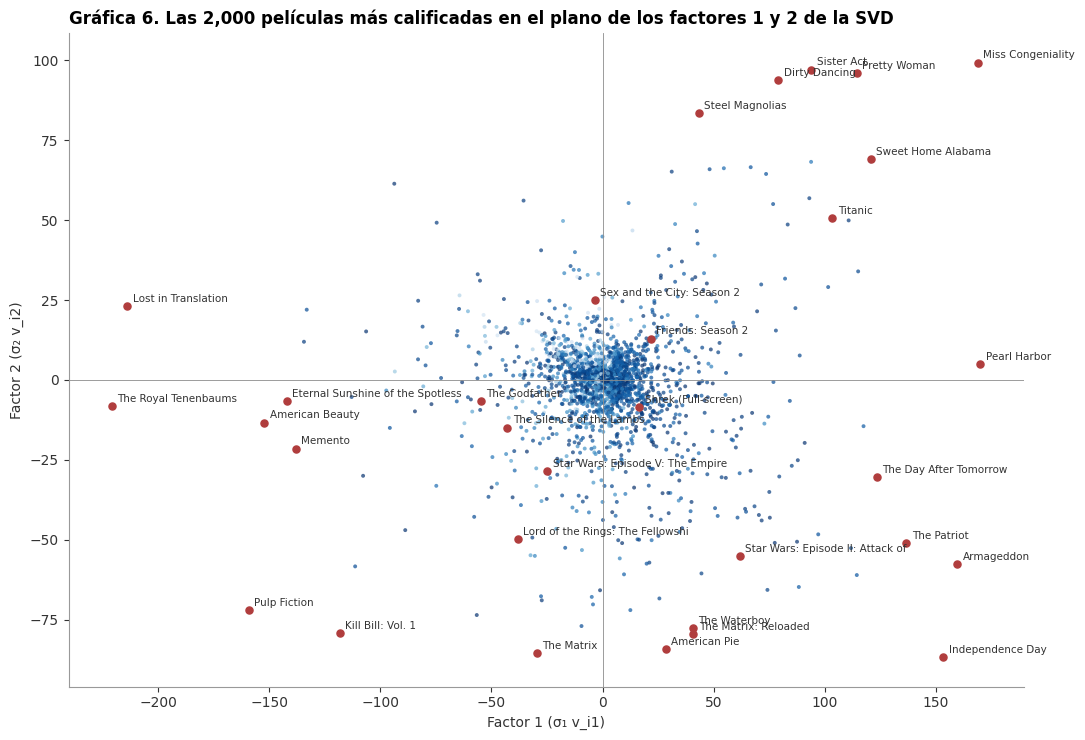

In [14]:
# Relación de los factores de la SVD con PCA del SGD, año, sesgo y popularidad; Gráfica 6: plano de los factores 1 y 2
variables = pd.DataFrame({"PC1 (SGD)": Z_pca[:, 0], "PC2 (SGD)": Z_pca[:, 1], "año": anio,
                          "sesgo b_i": svd["bi"][top], "log10 ratings": np.log10(peliculas.loc[top, "n_train"].to_numpy())})
correl = pd.DataFrame({f"factor {l + 1}": [np.corrcoef(V5[:, l], variables[c])[0, 1] for c in variables]
                       for l in range(5)}, index=variables.columns)
display(correl.round(3))

fig, ax = plt.subplots(figsize=(11, 7.5))
ax.scatter(V5[:, 0], V5[:, 1], c=anio, cmap="Blues", s=8, alpha=0.7, linewidths=0, vmin=1950)
extremos_12 = set(np.argsort(V5[:, 0])[:6]) | set(np.argsort(V5[:, 0])[-6:]) | set(np.argsort(V5[:, 1])[:6]) | set(np.argsort(V5[:, 1])[-6:])
for p in sorted(extremos_12 | set(pos_en_top.values())):
    ax.scatter(*V5[p, :2], s=26, color=ROJO, zorder=3)
    ax.annotate(peliculas.loc[top[p], "title"][:32], V5[p, :2], xytext=(4, 3), textcoords="offset points", fontsize=7.5,
                color=TINTA)
ax.axhline(0, color=GRIS, linewidth=0.6)
ax.axvline(0, color=GRIS, linewidth=0.6)
estilo_ejes(ax, "Gráfica 6. Las 2,000 películas más calificadas en el plano de los factores 1 y 2 de la SVD",
            "Factor 1 (σ₁ v_i1)", "Factor 2 (σ₂ v_i2)", rejilla=None)
plt.tight_layout()
plt.show()

**Observaciones: interpretación de los factores de la SVD**

Nombre propuesto para cada eje (el signo es arbitrario; ponemos primero el extremo positivo):

| Factor | Extremo positivo | Extremo negativo | Nombre propuesto | Relación más fuerte |
|---|---|---|---|---|
| 1 | *Pearl Harbor*, *Miss Congeniality*, *Armageddon*, *Independence Day* | *The Royal Tenenbaums*, *Lost in Translation*, *Pulp Fiction*, *Memento* | **comercial ↔ de autor** | PC1 del SGD (0.76) |
| 2 | *Miss Congeniality*, *Sister Act*, *Pretty Woman*, *Dirty Dancing*, *Steel Magnolias* | *Independence Day*, *The Matrix*, *American Pie*, *Kill Bill* | **romance y comedia "para ellas" ↔ acción y comedia "para ellos"** | PC2 del SGD (0.67) |
| 3 | *Forrest Gump*, *Braveheart*, *Titanic*, *Gladiator*, *Saving Private Ryan* | *The Day After Tomorrow*, *The League of Extraordinary Gentlemen*, *Van Helsing*, *XXX* | **clásicos de consenso ↔ acción mal valorada** | sesgo $b_i$ (0.48) |
| 4 | *The Patriot*, *El Señor de los Anillos*, *The Last Samurai*, *Troy*, *Master and Commander* | *Tommy Boy*, *Coming to America*, *The Waterboy*, *Ace Ventura*, *Spaceballs* | **épica seria ↔ comedia ligera** | año (0.26) |
| 5 | *Sweet Home Alabama*, *Napoleon Dynamite*, *Lost in Translation*, *My Big Fat Greek Wedding* | *Apocalypse Now*, *Jaws*, *Rocky*, *The Graduate*, *Taxi Driver*, *2001* | **lo reciente de los 2000 ↔ clásicos de los 70** | año (0.36) |

- **Como en la figura de Koren, Bell y Volinsky (2009),** el primer factor separa el cine **comercial** del cine **de
  autor**. En su figura 3, un eje va de comedias juveniles y de terror a dramas con
  protagonistas femeninas, y el otro de cine masivo y de fórmula a cine independiente y de culto. Son nuestros factores 2 y 1, y
  varias de las mismas películas aparecen en los extremos de las dos figuras (*The Royal Tenenbaums*, *Punch-Drunk Love*,
  *Armageddon*, *Coyote Ugly*, *The Sound of Music*, *Half Baked*). Los factores no se ajustaron para eso: salen de los
  ratings.
- **Relación con PCA y t-SNE.**
  - El factor 1 de la SVD es casi el PC1 del SGD (correlación **0.76**) y el factor 2 casi el PC2 (**0.67**). Dos
    métodos distintos (SVD con ceros sobre los residuos y SGD solo sobre lo observado) encuentran los mismos dos ejes
    principales del gusto.
  - La Gráfica 6 se parece a la 5a: *Pulp Fiction* y *Kill Bill* abajo a la izquierda (de autor, "para ellos"),
    *Miss Congeniality* y *Pretty Woman* arriba a la derecha (comercial, "para ellas"), *Independence Day* y
    *Armageddon* abajo a la derecha (comercial, acción).
  - Los factores 4 y 5 se relacionan con el año, lo que explica la isla de películas antiguas del t-SNE.
- **Lo que no es un factor.** El factor 3 se parece al sesgo $b_i$ (0.48), aunque la SVD es de los residuos del
  baseline. Distingue los clásicos que gustan a casi todos de la acción mal valorada, más allá de lo que captura el
  sesgo lineal.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">FACTORIZACIÓN · RESUMEN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">7. Resumen</span></div>

In [15]:
# Resultados acumulados (notebooks 2 y 3) y registro de memoria
nombres = ["Popularidad", "Baseline (completo)", "Baseline (S)", "kNN ítem-ítem", "kNN ítem-ítem (suma de similitudes)",
           "SVD truncada (completo)", "PureSVD (S)", "SVD-SGD (S)", "SVD-SGD (completo)", "NMF con máscara (S)"]
resultados = pd.DataFrame([json.load(open(RUTA_RESULTADOS / f"{m}.json", encoding="utf-8")) for m in nombres]).set_index("modelo")
columnas = ["escala", "rmse_probe", "rmse_probe_S", "P@10", "R@10", "NDCG@10", "segundos_entrenamiento"]
display(resultados[columnas].round(4))
display(pd.DataFrame(registro_ram).set_index("paso"))

,escala,rmse_probe,rmse_probe_S,P@10,R@10,NDCG@10,segundos_entrenamiento
modelo,,,,,,,
Popularidad,S,NaN,NaN,0.0053,0.0248,0.0146,NaN
Baseline (completo),completo (99 M),0.9822,0.9753,NaN,NaN,NaN,12.8619
Baseline (S),S,NaN,0.9760,0.0021,0.0097,0.0066,2.2725
kNN ítem-ítem,S,NaN,0.9312,0.0036,0.0181,0.0109,110.1400
kNN ítem-ítem (suma de similitudes),S,NaN,NaN,0.0162,0.0780,0.0490,NaN
SVD truncada (completo),completo (99 M),0.9666,0.9581,0.0034,0.0163,0.0105,203.6674
PureSVD (S),S,NaN,NaN,0.0189,0.0915,0.0554,112.3228
SVD-SGD (S),S,NaN,0.9106,0.0048,0.0221,0.0138,337.5744
SVD-SGD (completo),completo (99 M),0.9130,0.9043,0.0053,0.0252,0.0149,1634.6674


,RAM del proceso,RAM libre del sistema
paso,,
inicio,235.5 MB,7.73 GB
1. datos,1.93 GB,6.03 GB
2. SVD truncada,2.15 GB,4.73 GB
2. SVD truncada evaluada,1.96 GB,4.96 GB
3. PureSVD,2.00 GB,4.95 GB
4. rejilla SGD en S,2.21 GB,5.82 GB
4. SGD en S evaluado,2.07 GB,5.94 GB
4. SGD completo,797.2 MB,7.27 GB
5. rejilla NMF,816.1 MB,7.27 GB


**Resumen**

| Modelo | Escala | RMSE probe | RMSE probe S | P@10 | R@10 | NDCG@10 |
|---|---|---|---|---|---|---|
| Baseline | completo | 0.9822 | 0.9753 | — | — | — |
| SVD truncada, residuos ($k = 43$) | completo | 0.9666 | 0.9581 | 0.0034 | 0.0163 | 0.0105 |
| **SVD-SGD** ($f = 50$, $\lambda = 0.015$) | **completo** | **0.9130** | **0.9043** | 0.0053 | 0.0252 | 0.0149 |
| SVD-SGD | S | — | 0.9106 | 0.0048 | 0.0221 | 0.0138 |
| NMF con máscara ($k = 10$) | S | — | 0.9470 | 0.0054 | 0.0244 | 0.0154 |
| **PureSVD** ($k = 100$) | S | — | — | **0.0189** | **0.0915** | **0.0554** |
| Cinematch | completo | 0.9474 | — | — | — | — |

- **Predicción.** El SVD-SGD con sesgos es el mejor predictor de la práctica y supera a Cinematch en **3.6 %** en el
  probe completo. Lo que marca la diferencia es entrenar **solo con los ratings observados**: la SVD truncada, con los
  ceros impuestos, queda 2 % arriba de Cinematch.
- **Top-N.** PureSVD, que **sí** usa los ceros, es el mejor recomendador top-N hasta ahora. La misma descomposición
  sirve para una tarea o para la otra según cómo se trate lo no observado.
- **Interpretación.** Los dos primeros ejes del gusto (comercial ↔ de autor; romance ↔ acción) aparecen igual en la
  SVD, en el PCA de los factores del SGD y en la NMF.
- **Memoria.** El pico fue de **2.21 GB** del proceso, durante la rejilla de SGD en S, todavía con los arreglos
  completos en memoria.